# 📊 Telco Customer Churn — Complete ML Practicals (Colab Notebook)

All 7 practicals are applied to **one dataset: Telco Customer Churn** (`WA_Fn-UseC_-Telco-Customer-Churn.csv`).
Tasks that were written for other datasets (Bike Sharing, Diabetes, Country-data, Marketing Campaign, Credit-Card Fraud, Sleep) have been **mapped to the equivalent Telco columns**.

| # | Practical | What it uses in Telco |
|---|-----------|-----------------------|
| 1 | Preprocessing + EDA | Missing `TotalCharges`, churn distribution, churn by tenure / contract / internet service |
| 2 | Simple & Multiple Linear Regression | `tenure` → `TotalCharges`; then all numeric features |
| 3 | KNN, Naive Bayes, Logistic Regression | Predict `Churn` (Yes/No) |
| 4 | K-Means | Customer segments → highest-risk cluster + top-10 priority customers |
| 5 | GMM vs K-Means | Soft customer segmentation |
| 6 | Bagging, Random Forest vs Decision Tree | Churn class precision / recall / F1 |
| 7 | Bagging with 3 base estimators + **.pkl + app.py + deployment** | Streamlit web app |

**How to run:** `Runtime → Run all`, then upload your Telco CSV when asked in Step 0.

## Imports & load dataset

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import glob, pickle, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42

# Upload the Telco CSV (works in Colab); falls back to a CSV in the current folder otherwise
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]
except ImportError:
    CSV_PATH = glob.glob('*.csv')[0]

df = pd.read_csv(CSV_PATH)
print('Loaded:', CSV_PATH)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Loaded: WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
#  Data Preprocessing & EDA
**Tasks:** handle missing values, show shape / column descriptions / target distribution, and EDA of churn by (tenure group ≈ "hour of day", Contract ≈ "season", InternetService ≈ "weather").

In [ ]:
print('Shape:', df.shape)
print('\nData types & non-null counts:')
df.info()

Shape: (7043, 21)

Data types & non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object

In [ ]:
col_desc = {
 'customerID':'Unique customer id', 'gender':'Male / Female', 'SeniorCitizen':'1 if customer is 65+, else 0',
 'Partner':'Has a partner', 'Dependents':'Has dependents', 'tenure':'Months the customer has stayed',
 'PhoneService':'Has phone service', 'MultipleLines':'Has multiple phone lines', 'InternetService':'DSL / Fiber optic / No',
 'OnlineSecurity':'Online security add-on', 'OnlineBackup':'Online backup add-on', 'DeviceProtection':'Device protection add-on',
 'TechSupport':'Tech support add-on', 'StreamingTV':'Streams TV', 'StreamingMovies':'Streams movies',
 'Contract':'Month-to-month / One year / Two year', 'PaperlessBilling':'Paperless billing',
 'PaymentMethod':'How the customer pays', 'MonthlyCharges':'Amount charged per month',
 'TotalCharges':'Total amount charged so far', 'Churn':'TARGET - did the customer leave? (Yes/No)'}
pd.DataFrame({'Column': col_desc.keys(), 'Description': col_desc.values(), 'Dtype': [str(df[c].dtype) for c in col_desc]})

,Column,Description,Dtype
0,customerID,Unique customer id,object
1,gender,Male / Female,object
2,SeniorCitizen,"1 if customer is 65+, else 0",int64
3,Partner,Has a partner,object
4,Dependents,Has dependents,object
5,tenure,Months the customer has stayed,int64
6,PhoneService,Has phone service,object
7,MultipleLines,Has multiple phone lines,object
8,InternetService,DSL / Fiber optic / No,object
9,OnlineSecurity,Online security add-on,object


In [ ]:
# --- Handling missing values ---
# TotalCharges is stored as text; brand-new customers (tenure = 0) have a blank " " value
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing values per column:')
print(df.isnull().sum()[lambda s: s > 0])
print('\nRows with missing TotalCharges have tenure =', df.loc[df['TotalCharges'].isnull(), 'tenure'].unique())

TC_BEFORE = df['TotalCharges'].copy()                       # keep a copy for the before/after plot in Practical 3
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())   # median imputation

print('\nMissing after imputation:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum(), '| Duplicate customerIDs:', df['customerID'].duplicated().sum())
df['Churn_flag'] = (df['Churn'] == 'Yes').astype(int)       # numeric target (1 = churned)
df.describe()

Missing values per column:
TotalCharges    11
dtype: int64

Rows with missing TotalCharges have tenure = [0]

Missing after imputation: 0
Duplicate rows: 0 | Duplicate customerIDs: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_flag
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928,0.265370
std,0.368612,24.559481,30.090047,2265.270398,0.441561
min,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.500000,402.225000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


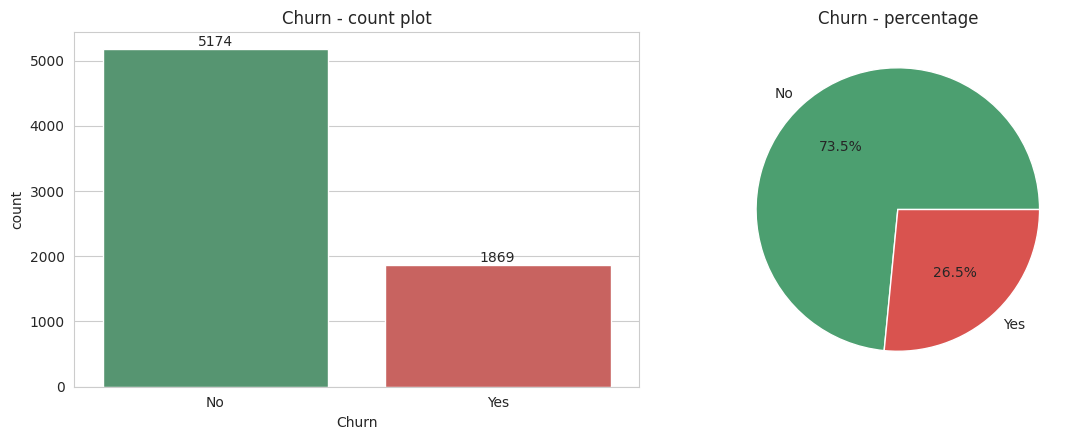

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [ ]:
# --- Target variable distribution ('Churn' is the target, like 'cnt' in the bike dataset) ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x='Churn', data=df, ax=ax[0], palette=['#4c9f70', '#d9534f'])
ax[0].set_title('Churn - count plot')
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
df['Churn'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#4c9f70', '#d9534f'], ax=ax[1], ylabel='')
ax[1].set_title('Churn - percentage')
plt.tight_layout(); plt.show()
print(df['Churn'].value_counts(normalize=True).round(3))

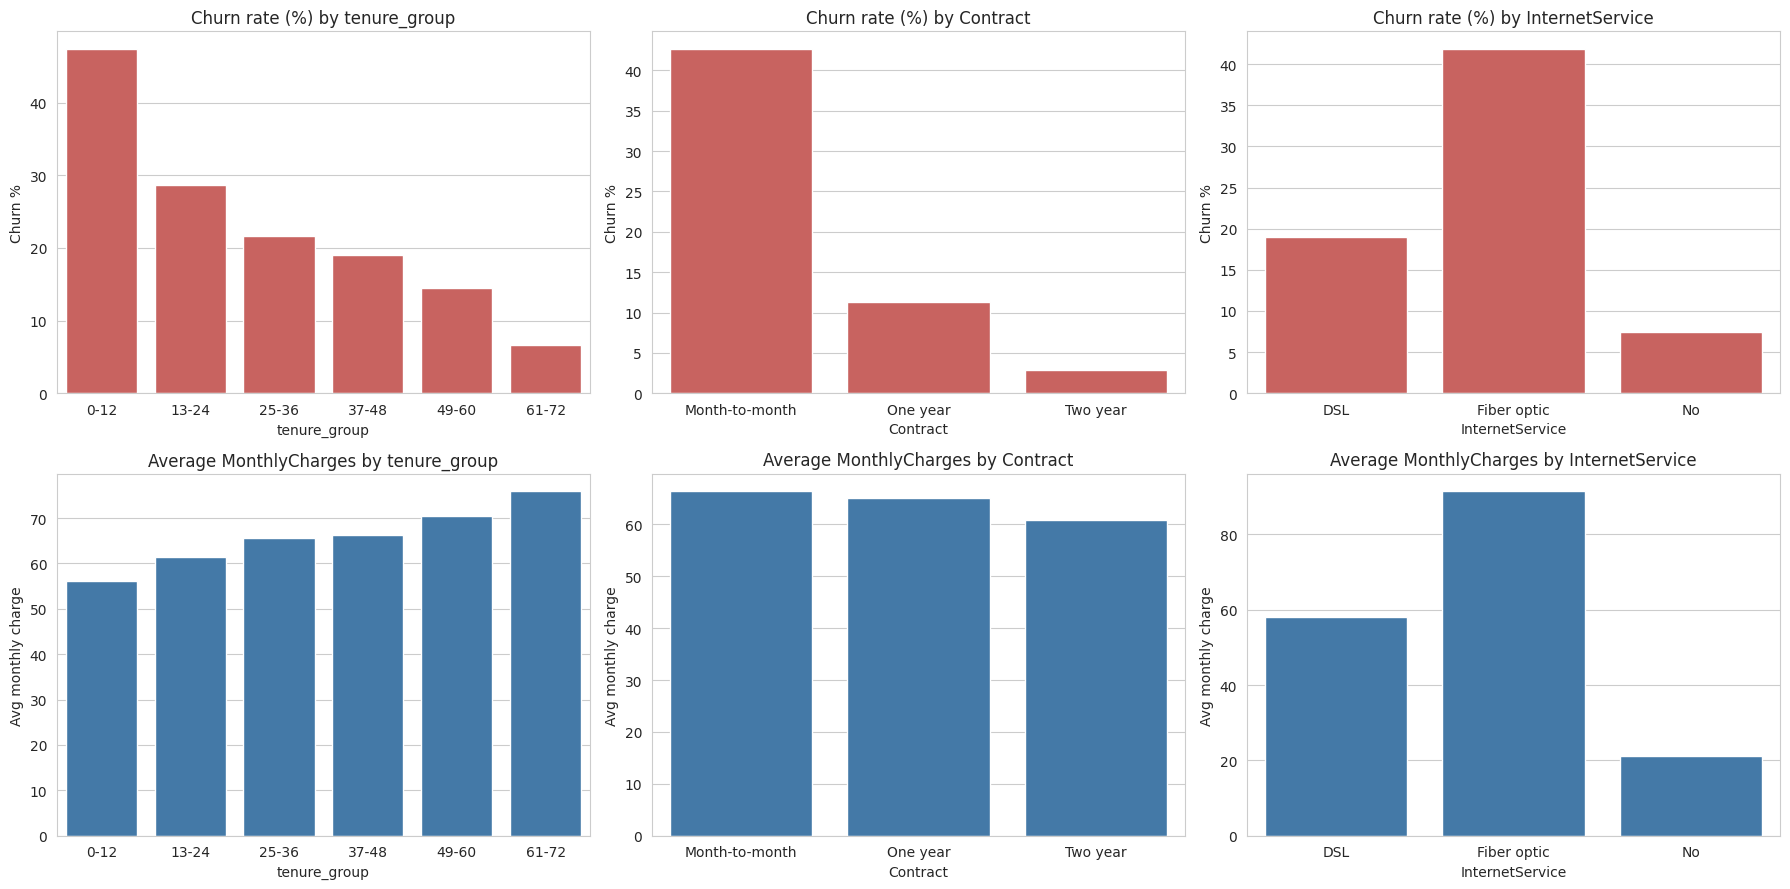

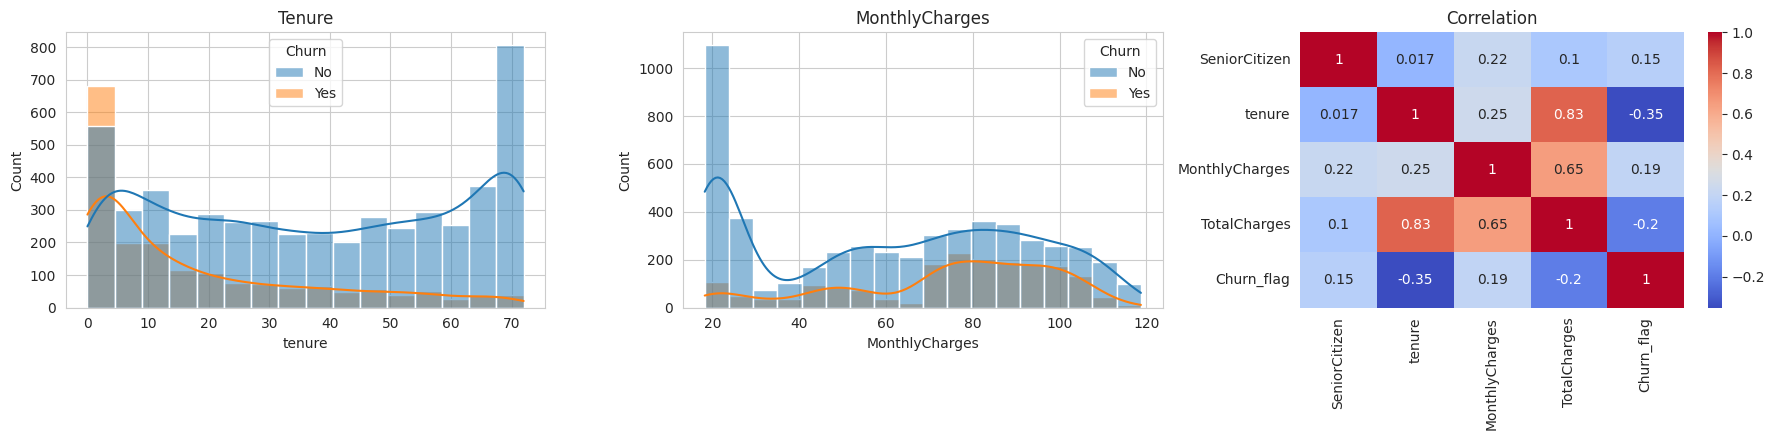

In [ ]:
# --- EDA: churn rate & average monthly charges by tenure group, contract, internet service ---
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1,12,24,36,48,60,72], labels=['0-12','13-24','25-36','37-48','49-60','61-72'])
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for j, col in enumerate(['tenure_group', 'Contract', 'InternetService']):
    rate = df.groupby(col, observed=True)['Churn_flag'].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[0, j], color='#d9534f')
    axes[0, j].set_title(f'Churn rate (%) by {col}'); axes[0, j].set_ylabel('Churn %')
    avg = df.groupby(col, observed=True)['MonthlyCharges'].mean()
    sns.barplot(x=avg.index.astype(str), y=avg.values, ax=axes[1, j], color='#337ab7')
    axes[1, j].set_title(f'Average MonthlyCharges by {col}'); axes[1, j].set_ylabel('Avg monthly charge')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=ax[0]); ax[0].set_title('Tenure')
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, ax=ax[1]); ax[1].set_title('MonthlyCharges')
sns.heatmap(df[['SeniorCitizen','tenure','MonthlyCharges','TotalCharges','Churn_flag']].corr(), annot=True, cmap='coolwarm', ax=ax[2]); ax[2].set_title('Correlation')
plt.tight_layout(); plt.show()
df = df.drop(columns='tenure_group')

**Insights:** churn is highest for *new* customers (low tenure), *month-to-month* contracts and *fiber-optic* internet users; long contracts and long tenure strongly reduce churn.

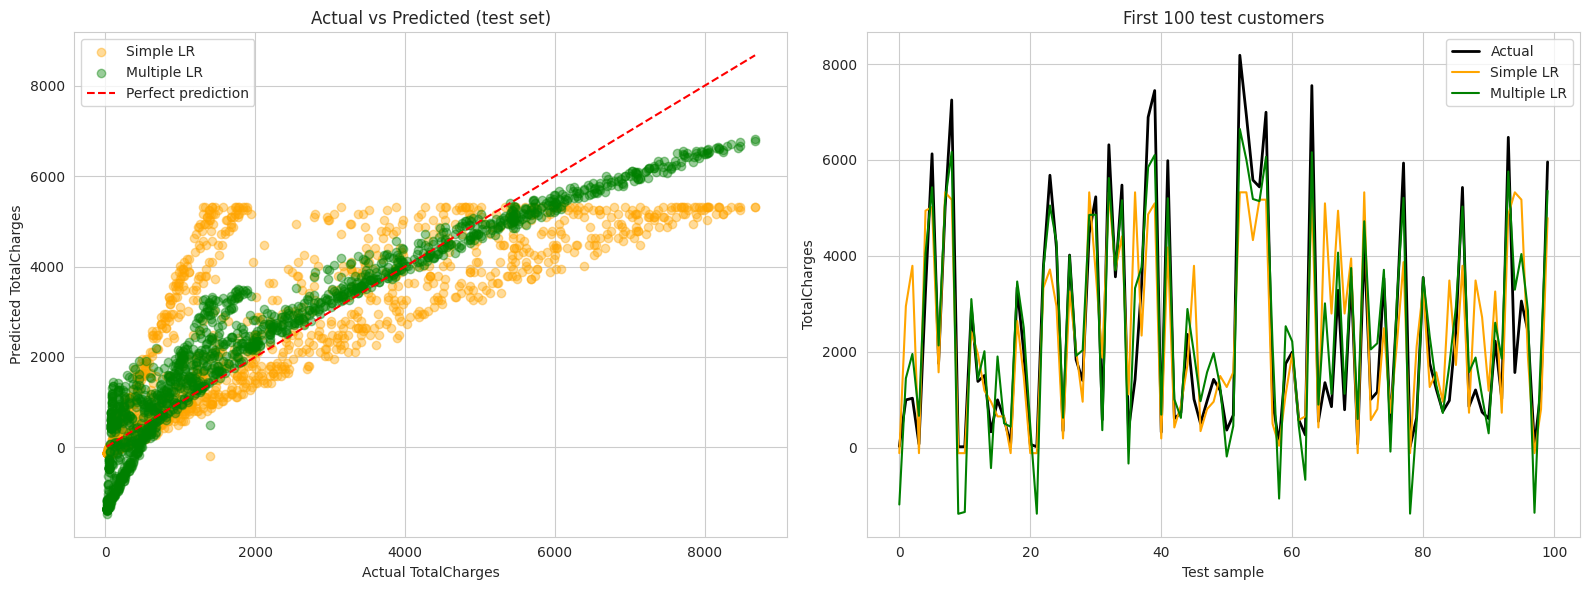

In [ ]:
# Actual vs Predicted for BOTH models on the same graph
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(ys_te, pred_s, alpha=0.4, label='Simple LR', color='orange')
ax[0].scatter(ym_te, pred_m, alpha=0.4, label='Multiple LR', color='green')
lims = [ys_te.min(), ys_te.max()]; ax[0].plot(lims, lims, 'r--', label='Perfect prediction')
ax[0].set_xlabel('Actual TotalCharges'); ax[0].set_ylabel('Predicted TotalCharges'); ax[0].set_title('Actual vs Predicted (test set)'); ax[0].legend()

n = 100   # first 100 test customers as a line chart
ax[1].plot(ys_te.values[:n], label='Actual', color='black', lw=2)
ax[1].plot(pred_s[:n], label='Simple LR', color='orange'); ax[1].plot(pred_m[:n], label='Multiple LR', color='green')
ax[1].set_title(f'First {n} test customers'); ax[1].set_xlabel('Test sample'); ax[1].set_ylabel('TotalCharges'); ax[1].legend()
plt.tight_layout(); plt.show()

---
#  KNN, Naive Bayes & Logistic Regression (Churn prediction)
Original: Diabetes (zero-value cleaning). **Telco mapping:** the data-quality issue is the blank `TotalCharges`, so the *before / after* histograms show this column.

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... TechSupport  \
0  No phone service             DSL             No  ...          No   
1                No             DSL            Yes  ...          No   
2                No             DSL            Yes  ...          No   
3  No phone service             DSL            Yes  ...         Yes   
4                No     Fiber optic             No  ...          No   

  StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No             

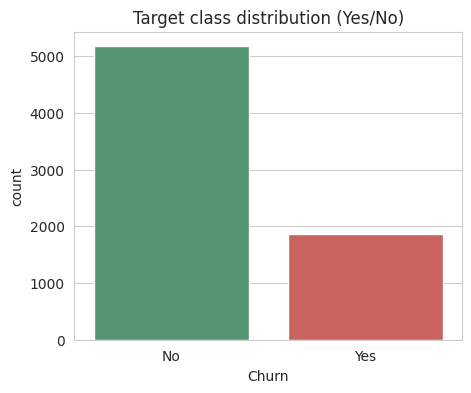

In [ ]:
print(df.head()); print('\nShape:', df.shape); print('\nColumns:', list(df.columns))
plt.figure(figsize=(5, 4)); sns.countplot(x='Churn', data=df, palette=['#4c9f70', '#d9534f']); plt.title('Target class distribution (Yes/No)'); plt.show()

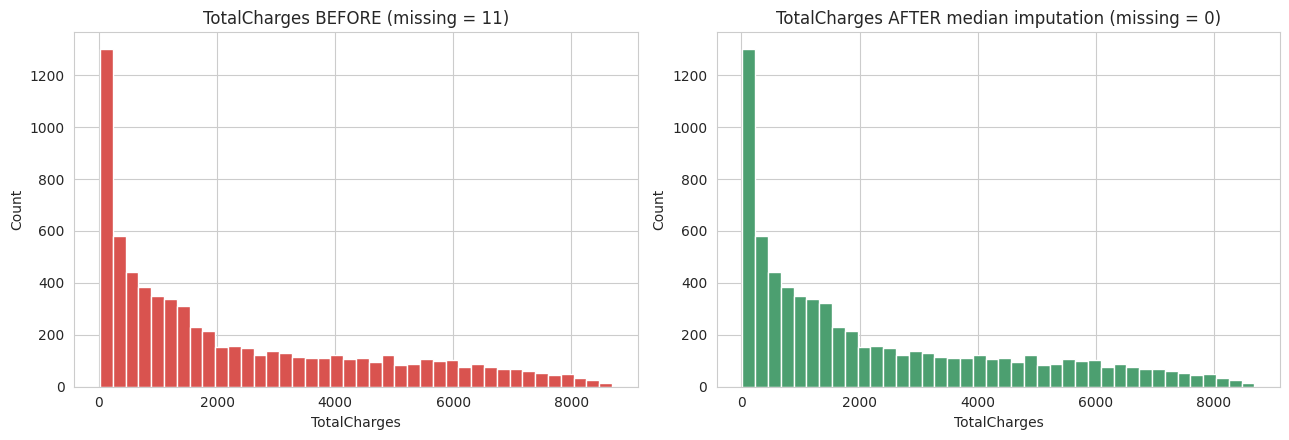

In [ ]:
# Before vs after treatment of TotalCharges (blank values -> median)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(TC_BEFORE.dropna(), bins=40, color='#d9534f'); ax[0].set_title(f'TotalCharges BEFORE (missing = {TC_BEFORE.isnull().sum()})')
ax[1].hist(df['TotalCharges'], bins=40, color='#4c9f70'); ax[1].set_title('TotalCharges AFTER median imputation (missing = 0)')
for a in ax: a.set_xlabel('TotalCharges'); a.set_ylabel('Count')
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Encode categoricals -> numeric feature matrix
X_all = pd.get_dummies(df.drop(columns=['customerID', 'Churn', 'Churn_flag']), drop_first=True).astype(float)
y_all = df['Churn_flag']
print('Feature matrix:', X_all.shape)

# StandardScaler on all features, 75:25 split (fit scaler on train only to avoid leakage)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.25, random_state=RANDOM_STATE, stratify=y_all)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

def cls_metrics(name, y_true, y_pred, y_prob=None):
    return {'Model': name, 'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred), 'F1-Score': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan}

results = []
# Logistic Regression (C=1, max_iter=1000)
lr = LogisticRegression(C=1, max_iter=1000).fit(X_tr_s, y_tr)
results.append(cls_metrics('Logistic Regression', y_te, lr.predict(X_te_s), lr.predict_proba(X_te_s)[:, 1]))
print(pd.DataFrame([results[-1]]).round(4).to_string(index=False))

Feature matrix: (7043, 30)
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8069     0.6616  0.5567    0.6047   0.8463


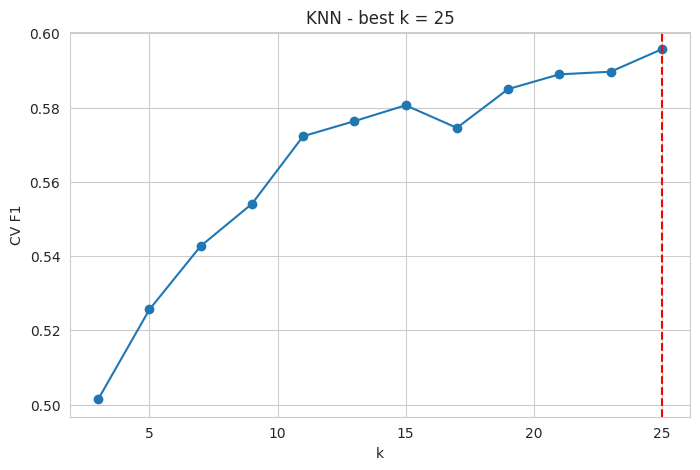

     Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
KNN (k=25)    0.7865     0.5991  0.5889     0.594   0.8227


In [ ]:
# KNN - choose k with 5-fold CV on the TRAIN set only
ks = range(3, 26, 2)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr_s, y_tr, cv=5, scoring='f1').mean() for k in ks]
best_k = list(ks)[int(np.argmax(cv_scores))]
plt.plot(list(ks), cv_scores, marker='o'); plt.axvline(best_k, color='r', ls='--'); plt.xlabel('k'); plt.ylabel('CV F1'); plt.title(f'KNN - best k = {best_k}'); plt.show()

knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr_s, y_tr)
results.append(cls_metrics(f'KNN (k={best_k})', y_te, knn.predict(X_te_s), knn.predict_proba(X_te_s)[:, 1]))
print(pd.DataFrame([results[-1]]).round(4).to_string(index=False))

In [ ]:
# Gaussian Naive Bayes
gnb = GaussianNB().fit(X_tr_s, y_tr)
results.append(cls_metrics('Gaussian Naive Bayes', y_te, gnb.predict(X_te_s), gnb.predict_proba(X_te_s)[:, 1]))
print(pd.DataFrame([results[-1]]).round(4).to_string(index=False))

               Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Gaussian Naive Bayes     0.661      0.431  0.8694    0.5763   0.8133


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.806900,0.661600,0.556700,0.604700,0.846300
KNN (k=25),0.786500,0.599100,0.588900,0.594000,0.822700
Gaussian Naive Bayes,0.661000,0.431000,0.869400,0.576300,0.813300


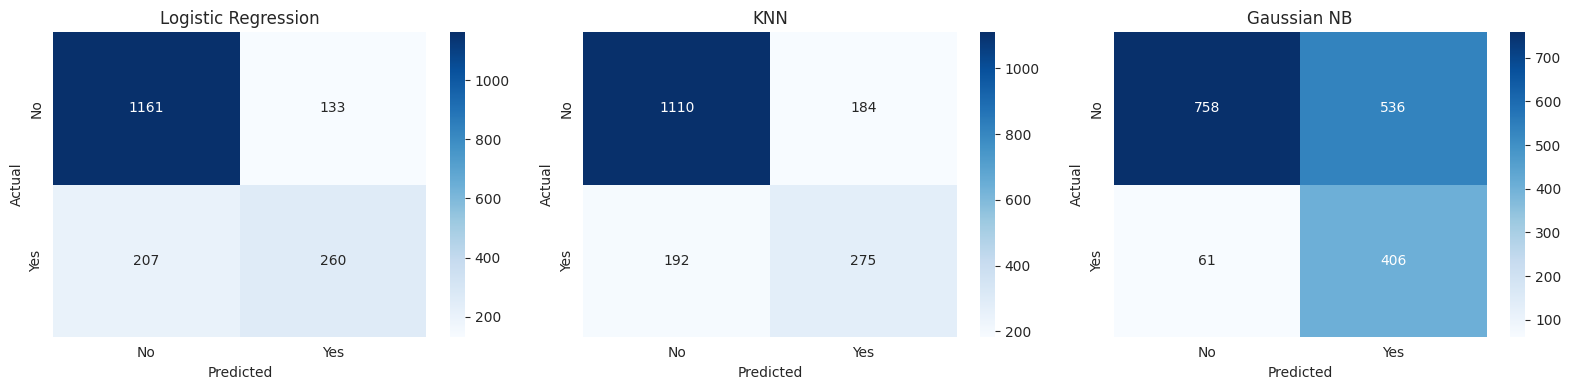

Best F1: Logistic Regression | Best Recall: Gaussian Naive Bayes | Best ROC-AUC: Logistic Regression


In [ ]:
# Final comparison table (3 models x 5 metrics)
comp3 = pd.DataFrame(results).set_index('Model').round(4)
display(comp3.style.highlight_max(axis=0, color='#c6efce'))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (m, mdl) in zip(ax, [('Logistic Regression', lr), ('KNN', knn), ('Gaussian NB', gnb)]):
    sns.heatmap(confusion_matrix(y_te, mdl.predict(X_te_s)), annot=True, fmt='d', cmap='Blues', ax=a, xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    a.set_title(m); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

best_f1 = comp3['F1-Score'].idxmax(); best_rec = comp3['Recall'].idxmax(); best_auc = comp3['ROC-AUC'].idxmax()
print(f'Best F1: {best_f1} | Best Recall: {best_rec} | Best ROC-AUC: {best_auc}')

### Recommendation (deployment)
For churn, a **false negative** (missing a customer who will leave) costs more than a **false alarm** (giving a discount to someone who would have stayed), so **Recall and F1 for the churn class matter more than raw accuracy**.
Choose the model with the best **F1 / ROC-AUC** in the table above (normally **Logistic Regression**: well-calibrated probabilities, stable, fast and interpretable). Gaussian Naive Bayes usually gives the highest recall but many false alarms; KNN is slower at prediction time and sensitive to scaling. Lower the decision threshold if you need even higher recall.

---
#  K-Means Clustering
Original: group countries and find the most underdeveloped cluster. **Telco mapping:** group customers by `tenure`, `MonthlyCharges`, `TotalCharges` and find the **most at-risk cluster** where retention effort will have the greatest impact.

Shape: (7043, 3)


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


Missing values:
 tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


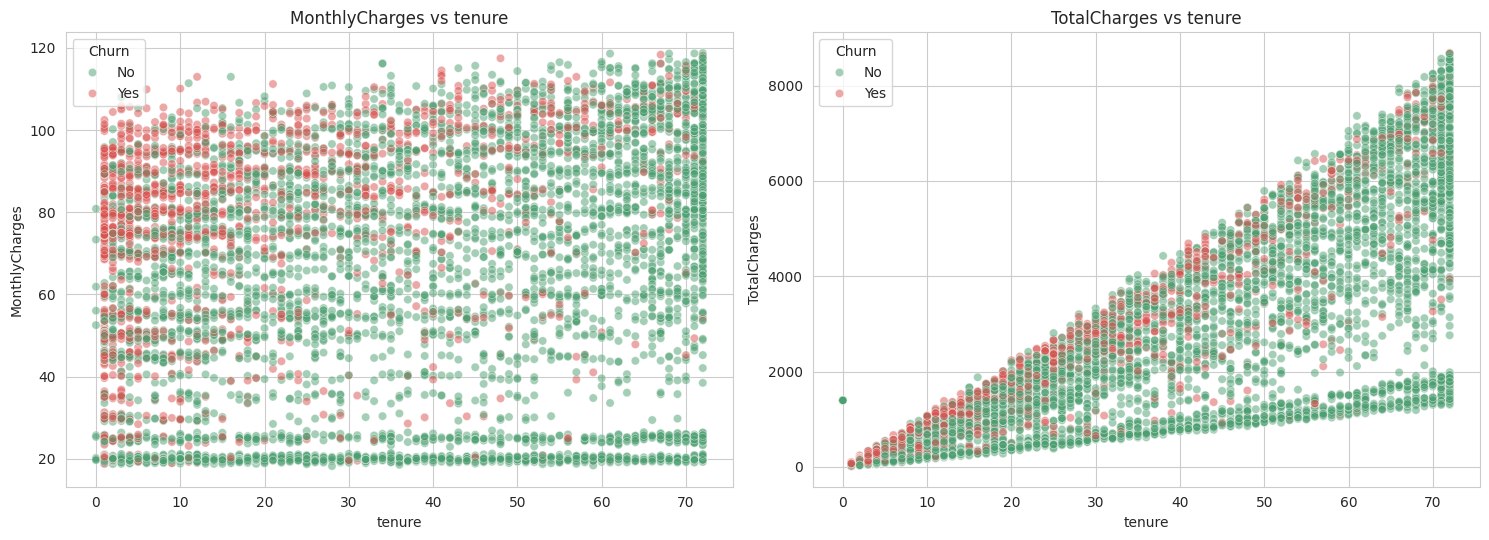

In [ ]:
from sklearn.cluster import KMeans
cl_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
print('Shape:', df[cl_features].shape); display(df[cl_features].describe()); print('Missing values:\n', df[cl_features].isnull().sum())

# EDA scatter plots - look for visually distinct groups
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn', alpha=0.5, ax=ax[0], palette=['#4c9f70', '#d9534f']); ax[0].set_title('MonthlyCharges vs tenure')
sns.scatterplot(data=df, x='tenure', y='TotalCharges', hue='Churn', alpha=0.5, ax=ax[1], palette=['#4c9f70', '#d9534f']); ax[1].set_title('TotalCharges vs tenure')
plt.tight_layout(); plt.show()

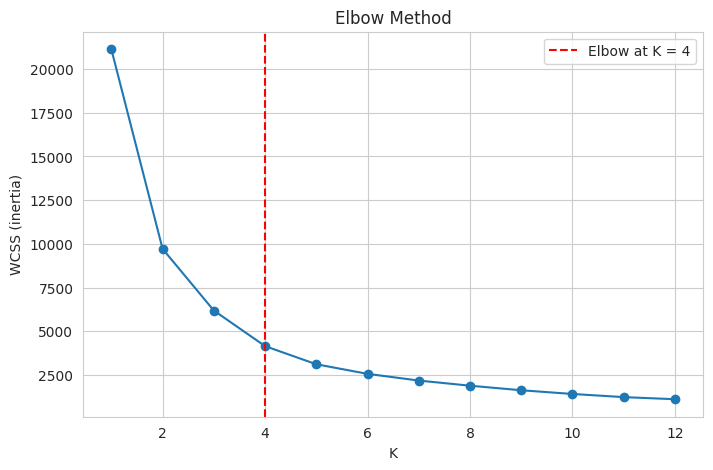

Optimal K = 4


In [ ]:
# StandardScaler - needed because units differ (months vs currency)
sc4 = StandardScaler(); Xc = sc4.fit_transform(df[cl_features])

# Elbow method (WCSS for K = 1..12)
ks = list(range(1, 13)); wcss = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc).inertia_ for k in ks]

def find_elbow(ks, vals):      # point farthest from the straight line joining first & last point (normalised)
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); v = np.array(vals); v = (v - v.min()) / (v.max() - v.min())
    d = np.abs((v[-1] - v[0]) * x - (x[-1] - x[0]) * v + x[-1] * v[0] - v[-1] * x[0])
    return ks[int(np.argmax(d))]
k_opt = find_elbow(ks, wcss)
plt.plot(ks, wcss, marker='o'); plt.axvline(k_opt, color='r', ls='--', label=f'Elbow at K = {k_opt}')
plt.xlabel('K'); plt.ylabel('WCSS (inertia)'); plt.title('Elbow Method'); plt.legend(); plt.show()
print('Optimal K =', k_opt)

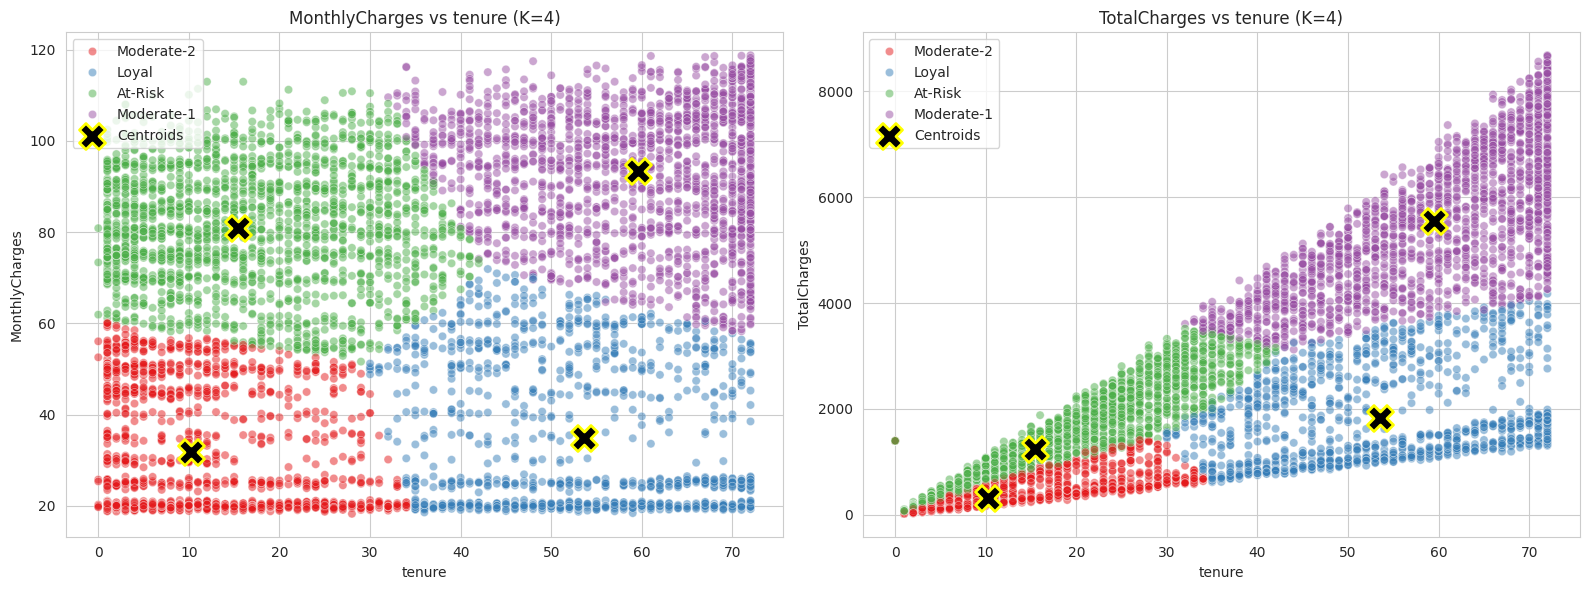

In [ ]:
km = KMeans(n_clusters=k_opt, n_init=10, random_state=RANDOM_STATE).fit(Xc)
df['Cluster'] = km.labels_

# Name clusters by their churn rate (lowest -> 'Loyal', highest -> 'At-Risk')
rank = df.groupby('Cluster')['Churn_flag'].mean().sort_values().index.tolist()
names = {}
for i, c in enumerate(rank):
    names[c] = 'Loyal' if i == 0 else ('At-Risk' if i == len(rank) - 1 else ('Moderate' if len(rank) == 3 else f'Moderate-{i}'))
df['Segment'] = df['Cluster'].map(names)
centroids = sc4.inverse_transform(km.cluster_centers_)       # back to original units for plotting
cent = pd.DataFrame(centroids, columns=cl_features)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, (xcol, ycol) in zip(ax, [('tenure', 'MonthlyCharges'), ('tenure', 'TotalCharges')]):
    sns.scatterplot(data=df, x=xcol, y=ycol, hue='Segment', alpha=0.5, ax=a, palette='Set1')
    a.scatter(cent[xcol], cent[ycol], marker='X', s=350, c='black', edgecolors='yellow', linewidths=2, label='Centroids')
    a.set_title(f'{ycol} vs {xcol} (K={k_opt})'); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Cluster profile
profile = df.groupby('Segment').agg(Customers=('Cluster', 'size'), tenure=('tenure', 'mean'), MonthlyCharges=('MonthlyCharges', 'mean'),
                                    TotalCharges=('TotalCharges', 'mean'), SeniorCitizen=('SeniorCitizen', 'mean'), ChurnRate=('Churn_flag', 'mean')).round(2)
display(profile.sort_values('ChurnRate'))

at_risk = [c for c, n in names.items() if n == 'At-Risk'][0]
print(f"Most critical cluster: '{names[at_risk]}' (cluster {at_risk}) - churn rate {df.loc[df.Cluster==at_risk,'Churn_flag'].mean():.1%}")

# Top 10 customers to prioritise = ACTIVE customers in the at-risk cluster with highest risk score (high bill, very short tenure)
scaled = pd.DataFrame(Xc, columns=cl_features, index=df.index)
pool = df[(df.Cluster == at_risk) & (df.Churn == 'No')].copy()
pool['RiskScore'] = scaled.loc[pool.index, 'MonthlyCharges'] - scaled.loc[pool.index, 'tenure']
top10 = pool.sort_values('RiskScore', ascending=False).head(10)
print('\nTop 10 customers the retention team should prioritise:')
display(top10[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService', 'PaymentMethod', 'RiskScore']].round(2).reset_index(drop=True))
df = df.drop(columns=['Cluster', 'Segment'])

,Customers,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,ChurnRate
Segment,,,,,,
Loyal,1159,53.59,34.92,1836.58,0.08,0.05
Moderate-1,1904,59.53,93.31,5548.65,0.22,0.15
Moderate-2,1704,10.23,31.77,308.96,0.07,0.25
At-Risk,2276,15.42,80.78,1253.01,0.23,0.48


Most critical cluster: 'At-Risk' (cluster 3) - churn rate 48.2%

Top 10 customers the retention team should prioritise:


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod,RiskScore
0,2081-VEYEH,3,107.95,318.60,Month-to-month,Fiber optic,Electronic check,2.63
1,5760-IFJOZ,3,107.95,313.60,Month-to-month,Fiber optic,Mailed check,2.63
2,6734-GMPVK,5,105.30,550.60,Month-to-month,Fiber optic,Electronic check,2.46
3,3292-PBZEJ,11,111.40,1183.05,Month-to-month,Fiber optic,Electronic check,2.42
4,7379-FNIUJ,2,100.20,198.50,Month-to-month,Fiber optic,Electronic check,2.41
5,4132-KALRO,4,100.85,399.25,Month-to-month,Fiber optic,Mailed check,2.35
6,6645-MXQJT,2,97.10,184.15,Month-to-month,Fiber optic,Electronic check,2.31
7,1393-IMKZG,1,95.85,95.85,Month-to-month,Fiber optic,Electronic check,2.31
8,0771-WLCLA,16,112.95,1882.55,Month-to-month,Fiber optic,Electronic check,2.27
9,4929-XIHVW,2,95.50,181.65,Month-to-month,Fiber optic,Credit card (automatic),2.26


---
## Bagging & Random Forest vs Single Decision Tree
Original: fraud detection (Time, Amount scaled). **Telco mapping:** the *churn class* plays the role of the "fraud class" (rare, important class); `tenure`, `MonthlyCharges`, `TotalCharges` are the scaled columns.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

def make_bagging(base, n, **kw):       # works with old and new scikit-learn
    try: return BaggingClassifier(estimator=base, n_estimators=n, random_state=RANDOM_STATE, **kw)
    except TypeError: return BaggingClassifier(base_estimator=base, n_estimators=n, random_state=RANDOM_STATE, **kw)

X6 = X_all.copy()
X6[['tenure', 'MonthlyCharges', 'TotalCharges']] = StandardScaler().fit_transform(X6[['tenure', 'MonthlyCharges', 'TotalCharges']])
X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y_all, test_size=0.30, random_state=RANDOM_STATE, stratify=y_all)   # 70:30

def churn_metrics(name, model):
    p = model.predict(X6_te); return {'Model': name, 'Precision': precision_score(y6_te, p), 'Recall': recall_score(y6_te, p), 'F1-Score': f1_score(y6_te, p), 'Accuracy': accuracy_score(y6_te, p)}

dt  = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X6_tr, y6_tr)
bag = make_bagging(DecisionTreeClassifier(), 50, n_jobs=-1).fit(X6_tr, y6_tr)
rf  = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1).fit(X6_tr, y6_tr)
rows = [churn_metrics('Decision Tree', dt), churn_metrics('Bagging (50 trees)', bag), churn_metrics('Random Forest (100)', rf)]
print('Churn-class metrics - first three models'); display(pd.DataFrame(rows).set_index('Model').round(4))

Churn-class metrics - first three models


,Precision,Recall,F1-Score,Accuracy
Model,,,,
Decision Tree,0.4982,0.5027,0.5004,0.7336
Bagging (50 trees),0.6278,0.4991,0.5561,0.7885
Random Forest (100),0.6298,0.4973,0.5558,0.7889


Recall change after class_weight='balanced': 0.4973 -> 0.4777


,Precision,Recall,F1-Score,Accuracy
Model,,,,
Decision Tree,0.498200,0.502700,0.500400,0.733600
Bagging (50 trees),0.627800,0.499100,0.556100,0.788500
Random Forest (100),0.629800,0.497300,0.555800,0.788900
Random Forest (balanced),0.627600,0.477700,0.542500,0.786100


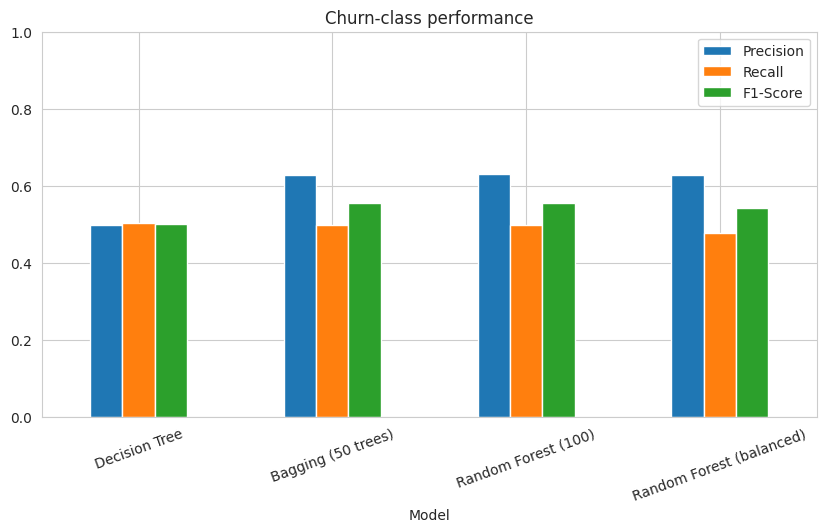

Best F1: Bagging (50 trees) | Best Recall: Decision Tree


In [ ]:
# Random Forest with class_weight='balanced'
rf_bal = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1).fit(X6_tr, y6_tr)
rows.append(churn_metrics('Random Forest (balanced)', rf_bal))
print(f"Recall change after class_weight='balanced': {rows[2]['Recall']:.4f} -> {rows[3]['Recall']:.4f}")

summary6 = pd.DataFrame(rows).set_index('Model').round(4); display(summary6.style.highlight_max(axis=0, color='#c6efce'))
summary6[['Precision', 'Recall', 'F1-Score']].plot(kind='bar', figsize=(10, 5)); plt.title('Churn-class performance'); plt.ylim(0, 1); plt.xticks(rotation=20); plt.show()
print('Best F1:', summary6['F1-Score'].idxmax(), '| Best Recall:', summary6['Recall'].idxmax())

### Recommendation for the company
A single Decision Tree over-fits (high variance). **Bagging and Random Forest reduce variance** and improve F1/precision; **Random Forest with `class_weight='balanced'`** (churners are only ~27% of data) normally gives the best **recall** for the churn class — i.e. it catches more customers who are about to leave. Pick the model that tops **F1 / Recall** in the table above (usually Random Forest, balanced) and tune the probability threshold if the retention budget allows more false alarms.

---
#  Bagging with different base estimators (+ `.pkl` files)
Bagging with **Decision Tree**, **KNN**, **Logistic Regression** (`n_estimators=20`, 75:25 split).
Each model is a full **Pipeline** (preprocessing + Bagging) built on the *raw* customer columns, so it can be saved as a `.pkl` and used directly by the web app.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

X_raw = df.drop(columns=['customerID', 'Churn', 'Churn_flag']); y_raw = df['Churn_flag']
num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']; cat_cols = [c for c in X_raw.columns if c not in num_cols]
def make_pre(): return ColumnTransformer([('num', StandardScaler(), num_cols), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)], sparse_threshold=0)

X7_tr, X7_te, y7_tr, y7_te = train_test_split(X_raw, y_raw, test_size=0.25, random_state=RANDOM_STATE, stratify=y_raw)   # 75:25
bases = {'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE), 'KNN': KNeighborsClassifier(n_neighbors=5), 'Logistic Regression': LogisticRegression(max_iter=1000)}

pipes, rows7 = {}, []
for name, base in bases.items():
    single = Pipeline([('pre', make_pre()), ('clf', base)]).fit(X7_tr, y7_tr)                              # base estimator alone
    bag_p = Pipeline([('pre', make_pre()), ('clf', make_bagging(base, 20))]).fit(X7_tr, y7_tr)             # Bagging, n_estimators = 20
    pipes[name] = bag_p
    a_single, a_bag = accuracy_score(y7_te, single.predict(X7_te)), accuracy_score(y7_te, bag_p.predict(X7_te))
    rows7.append({'Bagging base estimator': name, 'Single model accuracy': a_single, 'Bagging accuracy': a_bag, 'Gain from bagging': a_bag - a_single})
res7 = pd.DataFrame(rows7).set_index('Bagging base estimator'); display(res7.round(4))

,Single model accuracy,Bagging accuracy,Gain from bagging
Bagging base estimator,,,
Decision Tree,0.7342,0.7836,0.0494
KNN,0.7638,0.7575,-0.0062
Logistic Regression,0.8081,0.8069,-0.0011


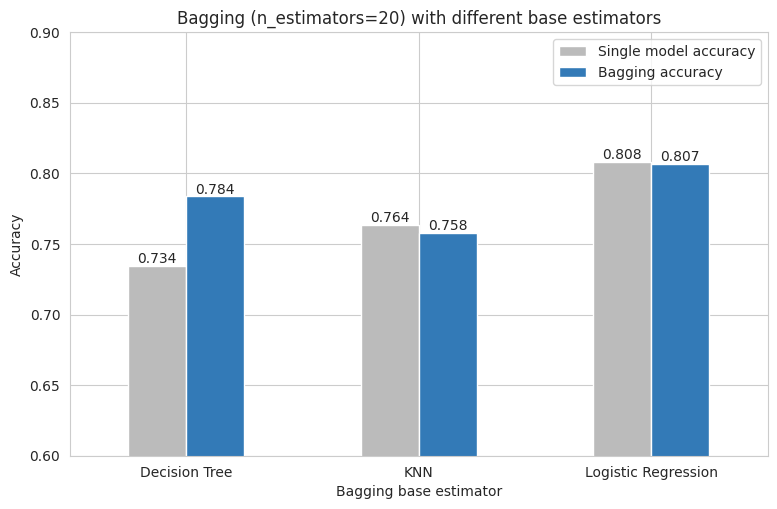

Best Bagging model: Logistic Regression (0.8069)
Largest gain from bagging: Decision Tree (+0.0494) | Smallest: KNN (-0.0062)


In [ ]:
ax = res7[['Single model accuracy', 'Bagging accuracy']].plot(kind='bar', figsize=(9, 5.5), color=['#bbbbbb', '#337ab7'])
for p in ax.patches: ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.ylim(0.6, 0.9); plt.ylabel('Accuracy'); plt.title('Bagging (n_estimators=20) with different base estimators'); plt.xticks(rotation=0); plt.show()

best7 = res7['Bagging accuracy'].idxmax(); gain = res7['Gain from bagging']
print(f"Best Bagging model: {best7} ({res7.loc[best7, 'Bagging accuracy']:.4f})")
print(f"Largest gain from bagging: {gain.idxmax()} ({gain.max():+.4f}) | Smallest: {gain.idxmin()} ({gain.min():+.4f})")

### Analysis — effect of the base estimator
* **Decision Tree** is an *unstable, high-variance* learner → bagging gives the **largest improvement** because averaging many different trees cancels the over-fitting.
* **KNN** is fairly stable (bootstrap samples change neighbours only slightly) → **small gain**, and it is the slowest at prediction time.
* **Logistic Regression** is a *low-variance, high-bias* linear model → bootstrapping barely changes it, so **almost no gain**; it is already strong on this mostly linear problem.
* Rule of thumb: bagging helps most when the base learner has **high variance** and does little for **stable / high-bias** learners.

In [ ]:
# Save the models as .pkl files (+ the best one separately) for the web app
file_map = {'Decision Tree': 'bagging_dt.pkl', 'KNN': 'bagging_knn.pkl', 'Logistic Regression': 'bagging_lr.pkl'}
for name, fn in file_map.items():
    with open(fn, 'wb') as f: pickle.dump(pipes[name], f)
with open('best_model.pkl', 'wb') as f: pickle.dump(pipes[best7], f)
json.dump(res7['Bagging accuracy'].round(4).to_dict(), open('model_accuracies.json', 'w'))

# Reload test with one raw customer row (like the first row in your dataset)
loaded = pickle.load(open('best_model.pkl', 'rb'))
sample = X_raw.iloc[[0]]; print(sample.T.head(8))
print('Churn probability for sample customer:', round(loaded.predict_proba(sample)[0, 1], 3))
import os; print('\nSaved files:', [f for f in os.listdir('.') if f.endswith(('.pkl', '.json'))])

                                0
gender                     Female
SeniorCitizen                   0
Partner                       Yes
Dependents                     No
tenure                          1
PhoneService                   No
MultipleLines    No phone service
InternetService               DSL
Churn probability for sample customer: 0.603

Saved files: ['model_accuracies.json', 'bagging_knn.pkl', 'bagging_dt.pkl', 'best_model.pkl', 'bagging_lr.pkl']


---
# 🌐 Web app (UI) — `app.py` with Streamlit, deployed from Colab
The next cell writes **`app.py`**, which loads the `.pkl` files and gives users a form to enter customer details and get the churn prediction.

In [ ]:
%%writefile app.py
import pickle
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Telco Customer Churn Predictor", page_icon="📉", layout="wide")

MODEL_FILES = {
    "Bagging + Decision Tree": "bagging_dt.pkl",
    "Bagging + KNN": "bagging_knn.pkl",
    "Bagging + Logistic Regression": "bagging_lr.pkl",
}

@st.cache_resource
def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)

st.title("📉 Telco Customer Churn Predictor")
st.caption("Bagging ensemble models trained on the Telco Customer Churn dataset")

with st.sidebar:
    st.header("Settings")
    model_name = st.selectbox("Choose model", list(MODEL_FILES))
    threshold = st.slider("Churn decision threshold", 0.10, 0.90, 0.50, 0.05)
    st.info("Lower threshold = catches more churners (higher recall) but more false alarms.")

st.subheader("Customer details")
c1, c2, c3 = st.columns(3)
with c1:
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior citizen", ["No", "Yes"])
    partner = st.selectbox("Partner", ["No", "Yes"])
    dependents = st.selectbox("Dependents", ["No", "Yes"])
    tenure = st.slider("Tenure (months)", 0, 72, 12)
    phone = st.selectbox("Phone service", ["Yes", "No"])
    multi = st.selectbox("Multiple lines", ["No", "Yes", "No phone service"])
with c2:
    internet = st.selectbox("Internet service", ["DSL", "Fiber optic", "No"])
    sec = st.selectbox("Online security", ["No", "Yes", "No internet service"])
    backup = st.selectbox("Online backup", ["No", "Yes", "No internet service"])
    protect = st.selectbox("Device protection", ["No", "Yes", "No internet service"])
    tech = st.selectbox("Tech support", ["No", "Yes", "No internet service"])
    tv = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
    movies = st.selectbox("Streaming movies", ["No", "Yes", "No internet service"])
with c3:
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless billing", ["Yes", "No"])
    payment = st.selectbox("Payment method", ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly = st.number_input("Monthly charges", 0.0, 200.0, 70.0, 0.05)
    total = st.number_input("Total charges", 0.0, 10000.0, float(round(70.0 * 12, 2)), 1.0)

if st.button("🔮 Predict churn", type="primary"):
    row = pd.DataFrame([{
        "gender": gender, "SeniorCitizen": 1 if senior == "Yes" else 0, "Partner": partner, "Dependents": dependents,
        "tenure": tenure, "PhoneService": phone, "MultipleLines": multi, "InternetService": internet,
        "OnlineSecurity": sec, "OnlineBackup": backup, "DeviceProtection": protect, "TechSupport": tech,
        "StreamingTV": tv, "StreamingMovies": movies, "Contract": contract, "PaperlessBilling": paperless,
        "PaymentMethod": payment, "MonthlyCharges": monthly, "TotalCharges": total,
    }])
    model = load_model(MODEL_FILES[model_name])
    prob = float(model.predict_proba(row)[0, 1])
    st.divider()
    left, right = st.columns(2)
    left.metric("Churn probability", f"{prob:.1%}")
    left.progress(min(max(prob, 0.0), 1.0))
    if prob >= threshold:
        right.error("⚠️ HIGH RISK - this customer is likely to churn. Consider a retention offer.")
    else:
        right.success("✅ LOW RISK - this customer is likely to stay.")
    with st.expander("Show submitted data"):
        st.dataframe(row.T.rename(columns={0: "value"}))

Writing app.py


In [ ]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn

Writing requirements.txt


### Deploy from Colab (public URL)
Run the cell below. It installs Streamlit, starts the app and creates a public **localtunnel** link.
1. Wait for a link like `https://xxxx.loca.lt`.
2. Open it → if it asks for a **tunnel password**, paste the IP address printed above the link.
3. Keep this cell running while people use the site (stop it with the ■ button).

In [ ]:
# OPTIONAL: ngrok instead of localtunnel (run only one of the two methods)
# !pip install -q pyngrok streamlit
# from pyngrok import ngrok
# import subprocess, time
# ngrok.set_auth_token("PASTE_YOUR_NGROK_TOKEN")
# subprocess.Popen(['streamlit', 'run', 'app.py', '--server.port', '8501', '--server.headless', 'true']); time.sleep(6)
# print('Public URL:', ngrok.connect(8501))

In [ ]:
!pip install -q pyngrok streamlit
from pyngrok import ngrok
import subprocess, time

ngrok.set_auth_token("3KrCMrJSPCxitpM6MtpPcN1LJGt_436CorcXu569A13qidaaX")
subprocess.Popen(['streamlit', 'run', 'app.py', '--server.port', '8501', '--server.headless', 'true'])
time.sleep(6)
print('Public URL:', ngrok.connect(8501))

Public URL: NgrokTunnel: "https://entrap-goofball-graveness.ngrok-free.dev" -> "http://localhost:8501"


### Permanent deployment (optional)
Download the project files, push them to a GitHub repo and deploy free on **Streamlit Community Cloud** (share.streamlit.io) → *New app* → pick `app.py`.

In [ ]:
import shutil
import os; os.makedirs('deploy_package', exist_ok=True)
for fn in ['app.py', 'requirements.txt', 'bagging_dt.pkl', 'bagging_knn.pkl', 'bagging_lr.pkl', 'best_model.pkl']: shutil.copy(fn, 'deploy_package/' + fn)
shutil.make_archive('telco_churn_app', 'zip', 'deploy_package')
try:
    from google.colab import files; files.download('telco_churn_app.zip')
except ImportError: print('Created telco_churn_app.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>